In [1]:
import sys
import pathlib
import pandas as pd

In [2]:
_p = pathlib.Path.cwd()

while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent

if not (_p / "db" / "dataraflow_db.py").exists():
    raise FileNotFoundError(
        "Could not find db/dataraflow_db.py. "
        "Make sure VS Code is using your DataraFlow project."
    )

sys.path.insert(0, str(_p))

print("Project root:", _p)
print("Database helper found:", (_p / "db" / "dataraflow_db.py").exists())

Project root: c:\Users\hp\Downloads\dataraflow-cohort-2-main
Database helper found: True


In [3]:
from db.dataraflow_db import run_query
print("Database query function imported succesfully.")

Database query function imported succesfully.


In [4]:
from db.practice import Practice
print("practice import works")

practice import works


In [5]:
london=run_query("SELECT * FROM week07.london_2014")
print("Data retrieve successfully")

Data retrieve successfully


In [6]:
london.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />
2,2014-1-3,11,8,6,9,5,2,94,76,54,...,31,12,0,50,29,69.0,7.11,2.0,Rain-Thunderstorm,219<br />
3,2014-1-4,9,6,3,8,6,2,93,85,65,...,31,12,5,35,21,39.0,9.91,4.0,Rain,211<br />
4,2014-1-5,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199<br />


In [7]:
print("Number of rows", london.shape[0])
print("Number of column", london.shape[1])

Number of rows 365
Number of column 23


In [8]:
print(london.columns.tolist())

['GMT', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC', 'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity', ' Mean Humidity', ' Min Humidity', ' Max Sea Level PressurehPa', ' Mean Sea Level PressurehPa', ' Min Sea Level PressurehPa', ' Max VisibilityKm', ' Mean VisibilityKm', ' Min VisibilitykM', ' Max Wind SpeedKm/h', ' Mean Wind SpeedKm/h', ' Max Gust SpeedKm/h', 'Precipitationmm', ' CloudCover', ' Events', 'WindDirDegrees<br />']


In [9]:
london.columns=london.columns.str.strip()
print(london.columns.tolist())

['GMT', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC', 'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity', 'Mean Humidity', 'Min Humidity', 'Max Sea Level PressurehPa', 'Mean Sea Level PressurehPa', 'Min Sea Level PressurehPa', 'Max VisibilityKm', 'Mean VisibilityKm', 'Min VisibilitykM', 'Max Wind SpeedKm/h', 'Mean Wind SpeedKm/h', 'Max Gust SpeedKm/h', 'Precipitationmm', 'CloudCover', 'Events', 'WindDirDegrees<br />']


In [10]:
london=london.rename(columns={"WindDirDegrees<br />": "WindDirDegrees"})
print(london.columns.tolist())

['GMT', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC', 'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity', 'Mean Humidity', 'Min Humidity', 'Max Sea Level PressurehPa', 'Mean Sea Level PressurehPa', 'Min Sea Level PressurehPa', 'Max VisibilityKm', 'Mean VisibilityKm', 'Min VisibilitykM', 'Max Wind SpeedKm/h', 'Mean Wind SpeedKm/h', 'Max Gust SpeedKm/h', 'Precipitationmm', 'CloudCover', 'Events', 'WindDirDegrees']


In [11]:
london["WindDirDegrees"]= (london["WindDirDegrees"].astype(str).str.replace("<br />", "", regex=False))
london["WindDirDegrees"].head()

0    186
1    214
2    219
3    211
4    199
Name: WindDirDegrees, dtype: str

In [12]:
london["WindDirDegrees"]= london["WindDirDegrees"].astype(int)
print(london["WindDirDegrees"].dtype)
london[["WindDirDegrees"]].head()

int64


,WindDirDegrees
0,186
1,214
2,219
3,211
4,199


In [13]:
london[london["WindDirDegrees"] >350]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
100,2014-4-11,16,12,9,5,4,2,71,53,28,...,31,18,10,13,8,NaN,0.00,1.0,NaN,351
110,2014-4-21,19,12,5,11,8,4,100,78,31,...,26,7,0,14,6,NaN,9.91,3.0,Fog-Rain-Thunderstorm,356
249,2014-9-7,21,17,13,14,12,8,94,71,41,...,23,10,2,11,6,NaN,0.00,4.0,NaN,354
250,2014-9-8,22,16,10,13,9,7,94,64,28,...,27,12,5,11,6,NaN,0.00,1.0,NaN,351
335,2014-12-2,8,7,6,7,4,2,100,80,62,...,31,11,1,27,13,NaN,1.02,5.0,Rain,359


In [14]:
london["GMT"]=pd.to_datetime(london["GMT"])
print(london.dtypes)

GMT                           datetime64[us]
Max TemperatureC                       int64
Mean TemperatureC                      int64
Min TemperatureC                       int64
Dew PointC                             int64
MeanDew PointC                         int64
Min DewpointC                          int64
Max Humidity                           int64
Mean Humidity                          int64
Min Humidity                           int64
Max Sea Level PressurehPa              int64
Mean Sea Level PressurehPa             int64
Min Sea Level PressurehPa              int64
Max VisibilityKm                       int64
Mean VisibilityKm                      int64
Min VisibilitykM                       int64
Max Wind SpeedKm/h                     int64
Mean Wind SpeedKm/h                    int64
Max Gust SpeedKm/h                   float64
Precipitationmm                      float64
CloudCover                           float64
Events                                   str
WindDirDeg

In [15]:
import datetime
london[london['GMT'] == datetime.datetime(2014,6,4)]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
154,2014-06-04,14,11,8,11,9,3,94,78,47,...,31,12,7,47,13,64.0,2.03,4.0,Rain-Thunderstorm,230


In [16]:
dates=london['GMT']
start=datetime.datetime(2014,12,8)
end=datetime.datetime(2014,12,12)
london[(dates >= start) & (dates <= end)]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
341,2014-12-08,7,4,1,2,1,-1,93,76,51,...,31,17,10,23,13,NaN,0.00,2.0,Rain,270
342,2014-12-09,12,6,-1,11,3,-1,100,86,64,...,31,15,3,37,14,52.0,0.25,5.0,Rain,224
343,2014-12-10,9,7,6,11,3,1,90,70,44,...,31,18,3,40,27,NaN,0.00,2.0,Rain,246
344,2014-12-11,10,8,5,6,3,2,82,72,51,...,31,15,10,40,31,NaN,0.25,2.0,Rain,246
345,2014-12-12,9,6,2,9,4,-1,94,79,59,...,31,11,3,40,26,55.0,1.02,3.0,Rain,253


In [17]:
#Rows from 1 April to 11 April 2014#
dates=london['GMT']
start=datetime.datetime(2014,4,1)
end=datetime.datetime(2014,4,14)
april_weather=london[(dates>=start) & (dates<=end)]
april_weather

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
90,2014-04-01,19,13,7,11,9,6,100,80,39,...,19,7,0,16,5,NaN,0.00,4.0,Fog-Rain,6
91,2014-04-02,18,14,11,11,9,7,88,71,48,...,10,8,5,23,13,NaN,0.00,1.0,Rain,85
92,2014-04-03,18,14,11,11,9,9,88,75,52,...,21,7,3,26,11,NaN,0.00,5.0,NaN,96
93,2014-04-04,15,12,9,10,8,6,88,71,46,...,31,11,2,24,14,NaN,0.00,5.0,NaN,253
94,2014-04-05,14,10,6,11,8,5,100,83,56,...,31,12,1,26,13,50.0,0.00,5.0,Fog-Rain,197
95,2014-04-06,16,14,12,12,12,11,94,88,67,...,31,12,5,35,21,48.0,2.03,6.0,Rain,213
96,2014-04-07,14,11,8,12,11,6,94,87,76,...,31,14,5,29,23,42.0,2.03,5.0,Rain,209
97,2014-04-08,14,9,5,6,3,-1,87,64,26,...,31,15,10,39,23,NaN,0.00,2.0,Rain,269
98,2014-04-09,17,10,4,7,6,3,93,68,38,...,31,14,6,23,13,NaN,0.00,2.0,NaN,261
99,2014-04-10,16,11,6,6,5,3,93,62,31,...,31,14,9,19,10,NaN,0.00,3.0,NaN,278


In [18]:
london.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
0,2014-01-01,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186
1,2014-01-02,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214
2,2014-01-03,11,8,6,9,5,2,94,76,54,...,31,12,0,50,29,69.0,7.11,2.0,Rain-Thunderstorm,219
3,2014-01-04,9,6,3,8,6,2,93,85,65,...,31,12,5,35,21,39.0,9.91,4.0,Rain,211
4,2014-01-05,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199


In [19]:
london.dtypes

GMT                           datetime64[us]
Max TemperatureC                       int64
Mean TemperatureC                      int64
Min TemperatureC                       int64
Dew PointC                             int64
MeanDew PointC                         int64
Min DewpointC                          int64
Max Humidity                           int64
Mean Humidity                          int64
Min Humidity                           int64
Max Sea Level PressurehPa              int64
Mean Sea Level PressurehPa             int64
Min Sea Level PressurehPa              int64
Max VisibilityKm                       int64
Mean VisibilityKm                      int64
Min VisibilitykM                       int64
Max Wind SpeedKm/h                     int64
Mean Wind SpeedKm/h                    int64
Max Gust SpeedKm/h                   float64
Precipitationmm                      float64
CloudCover                           float64
Events                                   str
WindDirDeg

In [20]:
#missing value code#
london.isnull().sum()

GMT                             0
Max TemperatureC                0
Mean TemperatureC               0
Min TemperatureC                0
Dew PointC                      0
MeanDew PointC                  0
Min DewpointC                   0
Max Humidity                    0
Mean Humidity                   0
Min Humidity                    0
Max Sea Level PressurehPa       0
Mean Sea Level PressurehPa      0
Min Sea Level PressurehPa       0
Max VisibilityKm                0
Mean VisibilityKm               0
Min VisibilitykM                0
Max Wind SpeedKm/h              0
Mean Wind SpeedKm/h             0
Max Gust SpeedKm/h            234
Precipitationmm                 0
CloudCover                     10
Events                        114
WindDirDegrees                  0
dtype: int64

In [21]:
london[london['Events'].isnull()]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
32,2014-02-02,10,8,5,4,3,1,93,71,43,...,31,16,10,37,24,47.0,0.00,2.0,NaN,216
33,2014-02-03,8,6,3,5,3,2,93,79,55,...,31,15,10,32,18,NaN,0.00,4.0,NaN,133
43,2014-02-13,8,6,3,2,1,-1,81,66,45,...,31,15,10,42,27,48.0,0.00,2.0,NaN,236
52,2014-02-22,12,8,4,5,3,1,87,68,38,...,31,16,10,29,21,NaN,0.00,2.0,NaN,228
63,2014-03-05,13,7,0,4,2,-1,100,72,40,...,31,15,8,21,6,NaN,0.25,1.0,NaN,248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
351,2014-12-18,13,12,11,11,11,10,94,85,74,...,31,12,10,37,29,60.0,0.00,6.0,NaN,245
358,2014-12-25,8,6,2,3,2,1,93,79,51,...,31,19,10,24,16,NaN,0.00,1.0,NaN,275
361,2014-12-28,6,2,-2,1,-2,-3,100,76,45,...,31,17,8,16,11,NaN,0.00,1.0,NaN,5
362,2014-12-29,6,1,-4,2,-1,-4,100,87,62,...,24,10,5,13,8,NaN,0.25,1.0,NaN,289


In [22]:
london['Events'] = london['Events'].fillna('')
london[london['Events'].isnull()]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees


In [23]:
#TASK 3. CLEANING DATA#
london["Max Gust SpeedKm/h"].isnull().sum()

np.int64(234)

In [24]:
missing_gust=london[london["Max Gust SpeedKm/h"].isnull()]
missing_gust.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
4,2014-01-05,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199
10,2014-01-11,9,4,0,7,3,-1,100,80,51,...,31,12,6,24,14,NaN,0.00,4.0,Rain,259
11,2014-01-12,10,4,-2,9,3,-2,100,91,79,...,31,9,1,32,10,NaN,0.51,6.0,Fog-Rain,126
12,2014-01-13,9,7,5,8,4,3,93,85,71,...,31,16,5,34,19,NaN,5.08,2.0,Rain,205
13,2014-01-14,7,4,1,5,2,0,100,82,55,...,31,15,10,21,13,NaN,0.25,3.0,Rain,242


In [25]:
warm_days = run_query("""
   SELECT GMT, [Max TemperatureC]
   FROM week07.london_2014
   WHERE [Max TemperatureC] >= 25
   ORDER BY [Max TemperatureC]
   DESC
""")
warm_days.head(10)

,GMT,Max TemperatureC
0,2014-7-18,30
1,2014-7-23,29
2,2014-7-24,29
3,2014-7-26,29
4,2014-7-17,29
5,2014-7-19,28
6,2014-7-20,27
7,2014-7-21,27
8,2014-7-22,27
9,2014-7-25,27


In [26]:
print("Number of warm_days:", len(warm_days))

Number of warm_days: 30


<Axes: >

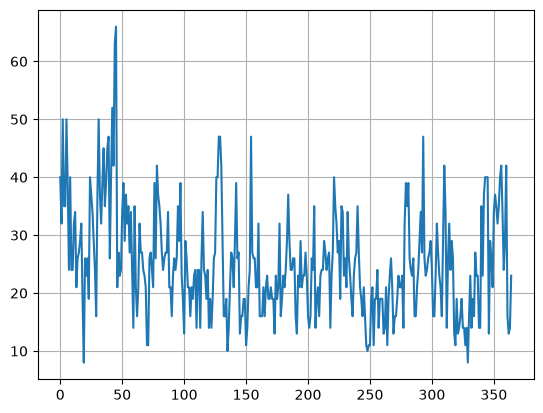

In [27]:
#visualization#
london['Max Wind SpeedKm/h'].plot(grid=True)

<Axes: >

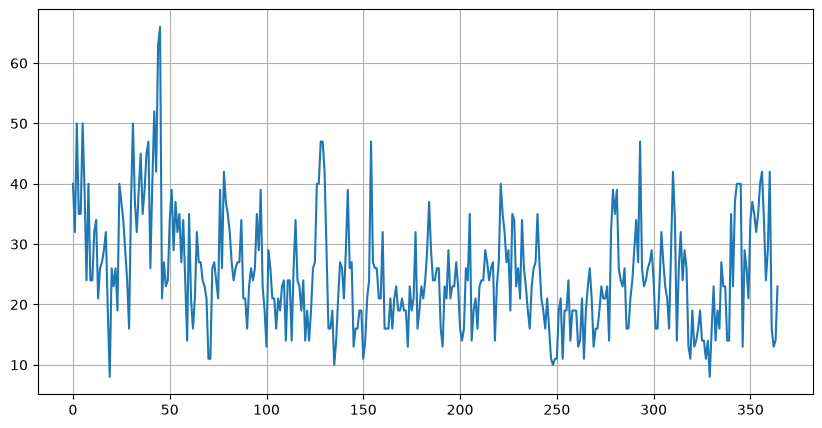

In [28]:
london['Max Wind SpeedKm/h'].plot(grid=True, figsize=(10,5))

<Axes: >

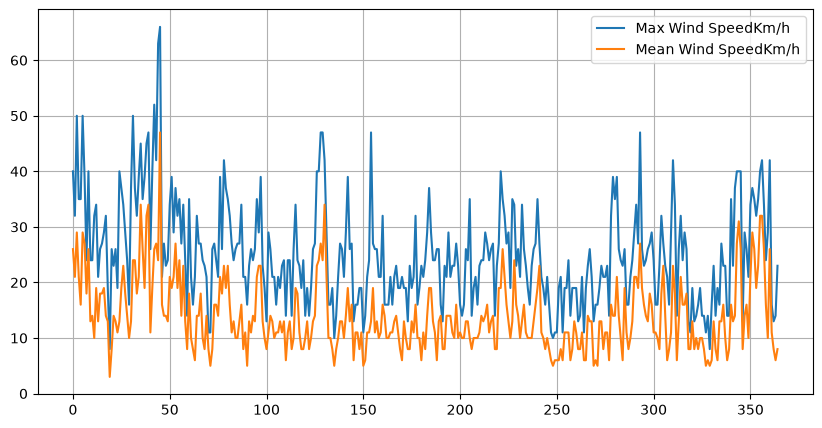

In [29]:
london[['Max Wind SpeedKm/h', 'Mean Wind SpeedKm/h']].plot(grid=True, figsize=(10,5))

<Axes: >

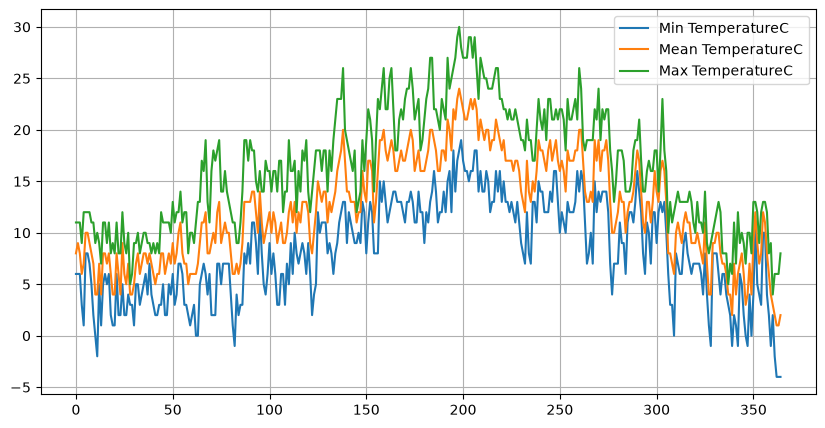

In [30]:
london[
    [
        "Min TemperatureC", 
        "Mean TemperatureC", 
        "Max TemperatureC"
    ]
].plot(
    grid=True,
    figsize=(10,5)
)

In [31]:
london.index=london['GMT']
london.head(2)

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
GMT,,,,,,,,,,,,,,,,,,,,,
2014-01-01,2014-01-01,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186
2014-01-02,2014-01-02,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214


In [32]:
london.loc[datetime.datetime(2014,1,1)]

GMT                           2014-01-01 00:00:00
Max TemperatureC                               11
Mean TemperatureC                               8
Min TemperatureC                                6
Dew PointC                                      9
MeanDew PointC                                  7
Min DewpointC                                   4
Max Humidity                                   94
Mean Humidity                                  86
Min Humidity                                   73
Max Sea Level PressurehPa                    1002
Mean Sea Level PressurehPa                    993
Min Sea Level PressurehPa                     984
Max VisibilityKm                               31
Mean VisibilityKm                              11
Min VisibilitykM                                2
Max Wind SpeedKm/h                             40
Mean Wind SpeedKm/h                            26
Max Gust SpeedKm/h                           66.0
Precipitationmm                              9.91


In [33]:
london.loc[datetime.datetime(2014,12,8) : datetime.datetime(201,12,12)]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
GMT,,,,,,,,,,,,,,,,,,,,,


In [34]:
london=london.sort_index()

<Axes: xlabel='GMT'>

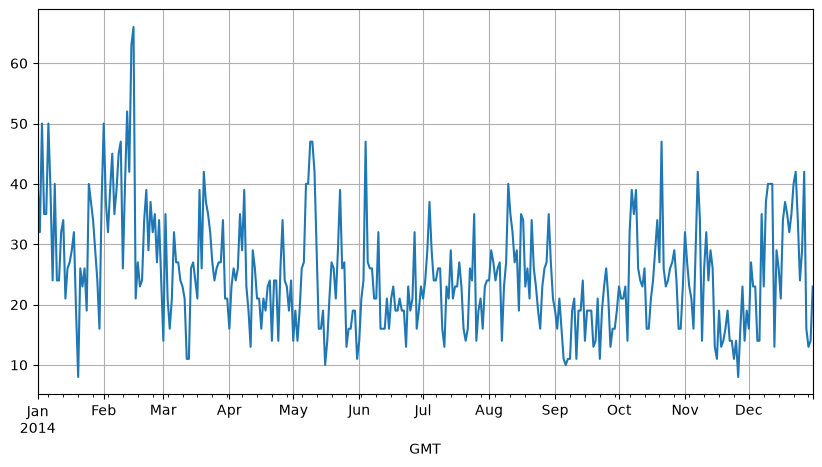

In [35]:
london['Max Wind SpeedKm/h'].plot(grid=True, figsize=(10,5))

<Axes: xlabel='GMT'>

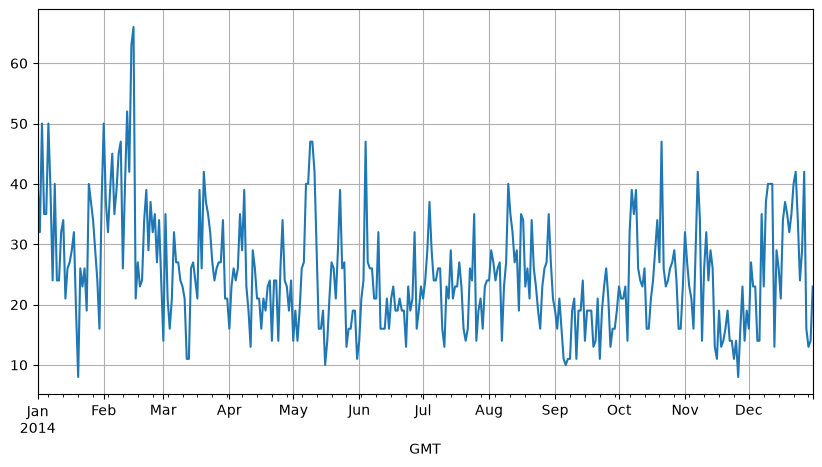

In [36]:

london['Max Wind SpeedKm/h'].plot(grid=True, figsize=(10,5))

In [37]:
#task plot mean humidity during spring march,.april,may#
london.index

DatetimeIndex(['2014-01-01', '2014-01-02', '2014-01-03', '2014-01-04',
               '2014-01-05', '2014-01-06', '2014-01-07', '2014-01-08',
               '2014-01-09', '2014-01-10',
               ...
               '2014-12-22', '2014-12-23', '2014-12-24', '2014-12-25',
               '2014-12-26', '2014-12-27', '2014-12-28', '2014-12-29',
               '2014-12-30', '2014-12-31'],
              dtype='datetime64[us]', name='GMT', length=365, freq=None)

In [38]:
spring_start=datetime.datetime(2014,3,1)
spring_end=datetime.datetime(2014,5,31)
spring=london.loc[spring_start:spring_end]
spring.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
GMT,,,,,,,,,,,,,,,,,,,,,
2014-03-01,2014-03-01,10,6,1,4,1,-2,100,75,35,...,31,9,0,14,8,NaN,0.00,2.0,Fog,273
2014-03-02,2014-03-02,10,6,2,6,4,1,93,82,56,...,31,12,6,35,18,53.0,0.25,4.0,Rain,190
2014-03-03,2014-03-03,9,6,3,5,3,2,93,83,63,...,31,14,10,21,10,NaN,0.76,3.0,Rain,191
2014-03-04,2014-03-04,11,6,0,5,2,-1,100,78,47,...,31,13,5,16,8,NaN,0.00,3.0,Fog-Rain,265
2014-03-05,2014-03-05,13,7,0,4,2,-1,100,72,40,...,31,15,8,21,6,NaN,0.25,1.0,,248


<Axes: xlabel='GMT'>

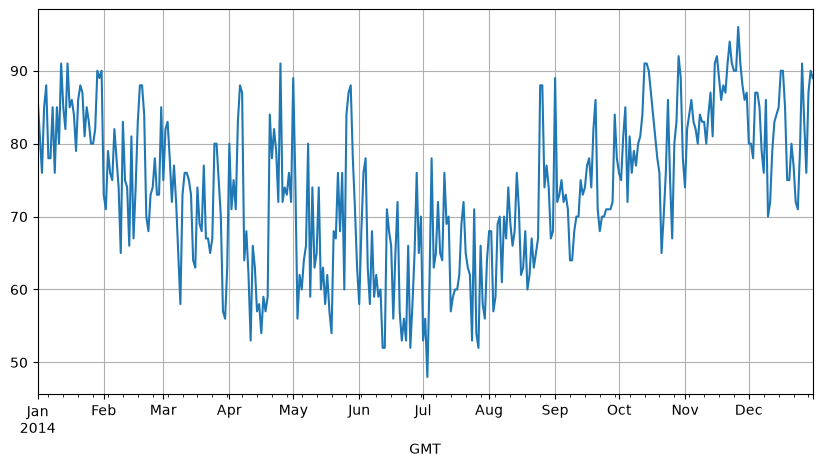

In [39]:
london['Mean Humidity'].plot(grid=True, figsize=(10,5))

In [40]:
london.to_csv("london_2014_cleannew.csv", index=False)
print("Saved! Cleaned data saved successfully")

Saved! Cleaned data saved successfully
